# 🩺 Week 7 · Class 1 — Your first classifier
**Ironhack Data Science & Machine Learning · Part-time**

Last week we predicted **numbers** (house prices). Today we predict a **category**: will a patient develop diabetes, **yes (1) or no (0)**?

**Running dataset for the week:** diabetes screening, 768 women, 8 medical measurements.

**By the end you can:** clean a medical dataset · build a baseline · fit **logistic regression** and **KNN** · read probabilities · move the **threshold** · explain why **scaling** matters · compare models fairly.

| ⏱️ | Section |
|---|---|
| 0–5' | 0 · Setup |
| 5–12' | 1 · Explore the data |
| 12–18' | 2 · Prepare: missing values and the split |
| 18–21' | 3 · The baseline |
| 21–40' | 4 · Logistic regression with one feature (regplots first) |
| 40–46' | 5 · Logistic regression with all features |
| 46–52' | 6 · The threshold |
| 52–82' | 7 · KNN: scaling, choosing k, StandardScaler vs MinMaxScaler |
| 82–86' | 8 · Decision boundaries |
| 86–90' | 9 · Results table and recap |

🧑‍💻 = we write it **together** · 🤔 = predict the answer **before** you run the cell.
📚 **At home:** Part B (SVM, Naive Bayes, solved exercises).

> 📦 `sns.regplot(..., logistic=True)` in section 4 needs the `statsmodels` package. In your project folder run `uv add statsmodels` (in Colab it is already installed).

---
## 0 · Setup
All the tools come from **scikit-learn** (`sklearn`), the same library as Week 6.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

sns.set_theme(style="whitegrid")
COLORS = {0: "#2F5BFF", 1: "#FF6B4A"}   # blue = no diabetes, orange = diabetes

The CSV is in the `data/` folder of the class repo. In Colab, upload it first (📁 icon on the left) and use `"diabetes.csv"`.

In [2]:
df = pd.read_csv("../data/diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


---
## 1 · Explore the data
One row = one patient. The **target** is `Outcome`: 1 = diabetes within 5 years, 0 = no diabetes.

| Column | Meaning |
|---|---|
| `Pregnancies` | number of pregnancies |
| `Glucose` | blood sugar 2 h after a glucose drink (mg/dL) |
| `BloodPressure` | diastolic blood pressure (mm Hg) |
| `SkinThickness` | skin fold on the arm (mm) |
| `Insulin` | insulin 2 h after the drink (µU/mL) |
| `BMI` | body mass index (kg/m²) |
| `DiabetesPedigreeFunction` | score for diabetes in the family |
| `Age` | years |

In [3]:
# shape and column types
print(df.shape)
df.info()

(768, 9)
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
# how many patients in each class?
df["Outcome"].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

In [5]:
# the same as percentages
df["Outcome"].value_counts(normalize=True).round(3)

Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64

💡 About **35 %** of the patients have diabetes. Remember this number: it comes back in section 3.

🧑‍💻 **Code with me:** look at the summary statistics. Do you see values that are **impossible** for a living person?

In [6]:
# summary statistics: look at the min row
df.describe().round(1)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.0,768.0,768.0,768.0,768.0,768.0,768.0,768.0,768.0
mean,3.8,120.9,69.1,20.5,79.8,32.0,0.5,33.2,0.3
std,3.4,32.0,19.4,16.0,115.2,7.9,0.3,11.8,0.5
min,0.0,0.0,0.0,0.0,0.0,0.0,0.1,21.0,0.0
25%,1.0,99.0,62.0,0.0,0.0,27.3,0.2,24.0,0.0
50%,3.0,117.0,72.0,23.0,30.5,32.0,0.4,29.0,0.0
75%,6.0,140.2,80.0,32.0,127.2,36.6,0.6,41.0,1.0
max,17.0,199.0,122.0,99.0,846.0,67.1,2.4,81.0,1.0


In [7]:
# count the zeros in every column
(df == 0).sum()

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

> ⚠️ Nobody has a glucose, BMI or blood pressure of **0**. In this dataset, `0` means **"not measured"**.
> `Pregnancies = 0` is fine (it is a real value), and `Outcome = 0` is the class "no diabetes".

Before cleaning, a first look: does glucose separate the two classes?

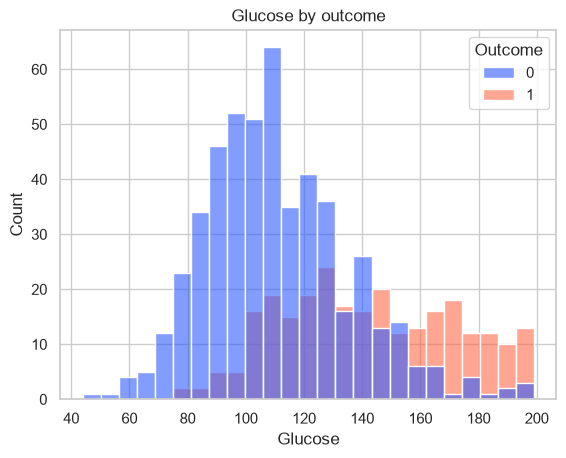

In [8]:
# glucose distribution for each class (zeros removed for the plot)
plot_df = df[df["Glucose"] > 0]
sns.histplot(data=plot_df, x="Glucose", hue="Outcome", palette=COLORS, bins=25, alpha=0.6)
plt.title("Glucose by outcome")
plt.show()

🤔 **Predict:** if you had to write **one rule** with glucose only (`if Glucose > ...: diabetes`), where would you put the cut? How many patients would land on the wrong side?

---
## 2 · Prepare: missing values and the split
### 2.1 Turn the fake zeros into missing values
`np.nan` means "missing" in pandas. We replace the zeros **only** in the 5 columns where 0 is impossible.

In [9]:
# replace 0 by NaN in the 5 columns where 0 is impossible
cols_zero_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[cols_zero_missing] = df[cols_zero_missing].replace(0, np.nan)
df.isna().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

We do **not** fill the missing values yet. Filling them now would use information from the test set (**data leakage**, Week 6). The pipeline will fill them later, learning the medians from the training set only.

### 2.2 Features, target and the split

In [10]:
# X = features, y = target
X = df.drop(columns="Outcome")
y = df["Outcome"]
X.shape, y.shape

((768, 8), (768,))

In [11]:
# 80 % train / 20 % test, same class balance in both parts
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(len(X_train), "train patients ·", len(X_test), "test patients")
print("diabetes share  train:", round(y_train.mean(), 3), "· test:", round(y_test.mean(), 3))

614 train patients · 154 test patients
diabetes share  train: 0.349 · test: 0.351


🤔 **Why `stratify=y`?** Without it, the random split could put, say, 30 % diabetes in train and 45 % in test. `stratify` keeps the **same proportion** (35 %) in both parts, so the test score is fair.

---
## 3 · The baseline
Before any real model: what score do we get **without learning anything**?

`DummyClassifier` always predicts the **most frequent class** ("no diabetes").

In [12]:
# a "model" that always predicts the majority class
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline.score(X_test, y_test)

0.6493506493506493

💡 `.score()` for a classifier = **accuracy** = share of correct predictions.

**65 % accuracy without learning anything!** Every model we build today must beat this number. A model at 66 % is almost useless.

---
## 4 · Logistic regression with one feature
Logistic regression works in two steps:
1. a **linear score**: $z = b_0 + b_1 \cdot \text{Glucose}$ (like last week)
2. the **sigmoid** squeezes $z$ into a probability: $p = \dfrac{1}{1 + e^{-z}}$, always between 0 and 1

Before any scikit-learn code, let's **look** at it. Seaborn's `regplot` draws a fitted curve on a scatter plot, like the regplots of Week 6.

We use the **training set** only (the test set stays hidden).

In [13]:
# one table with the training features and the target, for plotting
train = X_train.copy()
train["Outcome"] = y_train
train.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
353,1,90.0,62.0,12.0,43.0,27.2,0.580,24,0
711,5,126.0,78.0,27.0,22.0,29.6,0.439,40,0
373,2,105.0,58.0,40.0,94.0,34.9,0.225,25,0
46,1,146.0,56.0,NaN,NaN,29.7,0.564,29,0
682,0,95.0,64.0,39.0,105.0,44.6,0.366,22,0


### 4.1 A straight line vs an S-curve
The target is 0 or 1, so every dot sits on one of **two horizontal lines**. `y_jitter` moves the dots up and down a little so we can see how many there are.

🧑‍💻 **Code with me:** the same data, first with a **straight line** (last week's linear regression), then with `logistic=True`.

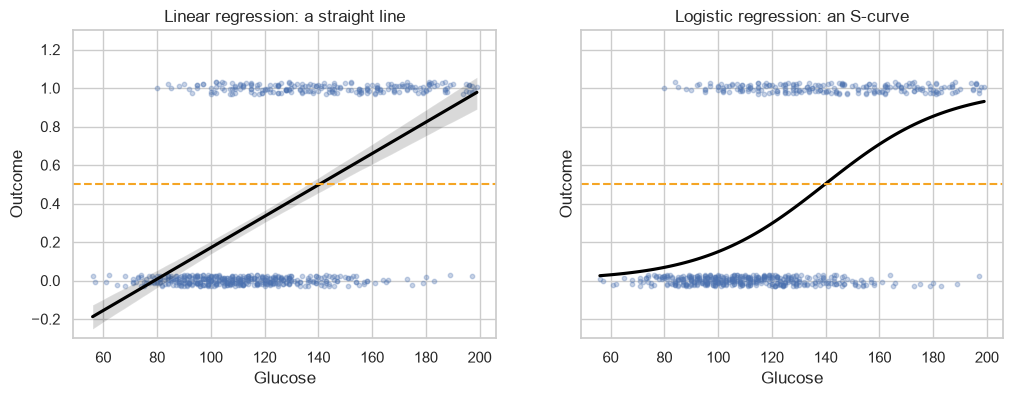

In [14]:
# left: straight line · right: logistic S-curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.regplot(data=train, x="Glucose", y="Outcome", y_jitter=0.03,
            scatter_kws={"s": 10, "alpha": 0.3}, line_kws={"color": "black"}, ax=axes[0])
axes[0].set_title("Linear regression: a straight line")

sns.regplot(data=train, x="Glucose", y="Outcome", y_jitter=0.03, logistic=True, ci=None,
            scatter_kws={"s": 10, "alpha": 0.3}, line_kws={"color": "black"}, ax=axes[1])
axes[1].set_title("Logistic regression: an S-curve")

for ax in axes:
    ax.axhline(0.5, ls="--", color="#F5A524")
    ax.set_ylim(-0.3, 1.3)
plt.show()

**How to read these two plots**
- **Dots at the bottom (0):** patients without diabetes · **dots at the top (1):** patients with diabetes.
- Low glucose → mostly dots at 0. High glucose → more and more dots at 1.
- **Left:** the straight line goes **below 0** for low glucose (about −0.2 at glucose 60), and it would pass **1** just above glucose 200. A "probability" of −0.2 makes no sense.
- **Right:** the S-curve stays **between 0 and 1**. Its height at a given glucose value = the **estimated probability of diabetes**.
- **Orange dashed line = 0.5.** Where the S-curve crosses it, the prediction changes from 0 to 1.

🤔 **Predict:** at which glucose value does the S-curve cross 0.5?

### 4.2 What does the S-curve estimate?
The curve estimates the **share of patients with diabetes** at each glucose level. Let's check it ourselves: cut glucose into groups of 15 mg/dL and compute the share of diabetes in each group.

In [15]:
# glucose groups of 15 mg/dL, then the share of diabetes in each group
train["glucose_group"] = pd.cut(train["Glucose"], bins=range(40, 215, 15))
groups = train.groupby("glucose_group", observed=True).agg(
    mean_glucose=("Glucose", "mean"),
    share_diabetes=("Outcome", "mean"),
    patients=("Outcome", "size"),
)
groups.round(2)

,mean_glucose,share_diabetes,patients
glucose_group,,,
"(55, 70]",62.43,0.00,7
"(70, 85]",79.67,0.06,49
"(85, 100]",93.98,0.11,111
"(100, 115]",108.18,0.25,127
"(115, 130]",123.25,0.30,119
"(130, 145]",138.37,0.47,68
"(145, 160]",152.33,0.57,49
"(160, 175]",167.50,0.84,38
"(175, 190]",182.61,0.87,31


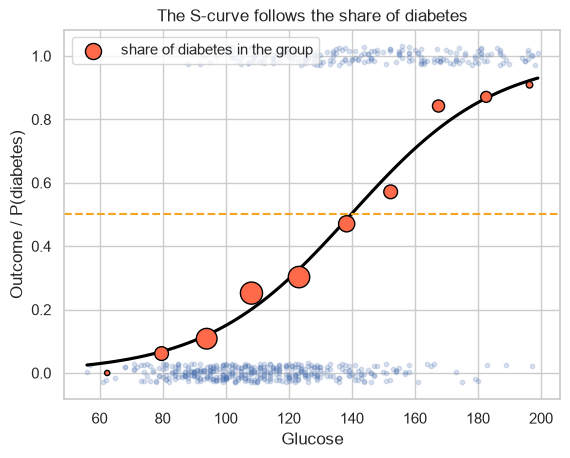

In [16]:
# the S-curve (black) and the real share in each group (orange dots)
sns.regplot(data=train, x="Glucose", y="Outcome", y_jitter=0.03, logistic=True, ci=None,
            scatter_kws={"s": 10, "alpha": 0.2}, line_kws={"color": "black"})
plt.scatter(groups["mean_glucose"], groups["share_diabetes"], s=groups["patients"] * 2,
            color="#FF6B4A", edgecolors="black", zorder=5, label="share of diabetes in the group")
plt.axhline(0.5, ls="--", color="#F5A524")
plt.ylabel("Outcome / P(diabetes)"); plt.legend(loc="upper left")
plt.title("The S-curve follows the share of diabetes")
plt.show()

💡 The orange dots (bigger = more patients) lie close to the black curve: **logistic regression draws a smooth version of "share of diabetes per glucose level"**.
- Glucose 70–100: about 1 patient in 10 (or fewer) has diabetes.
- Glucose 160+: more than 8 patients in 10 have diabetes.
- The curve crosses 0.5 around glucose **140**, exactly where the groups go from "mostly healthy" to "mostly diabetes".

### 4.3 Which feature tells us the most?
One S-curve per feature. The grey band marks where **90 % of the patients** are: read the curve **there**, because the ends of the curve rest on very few patients.

🤔 **Predict before running:** which feature will move the probability the most?

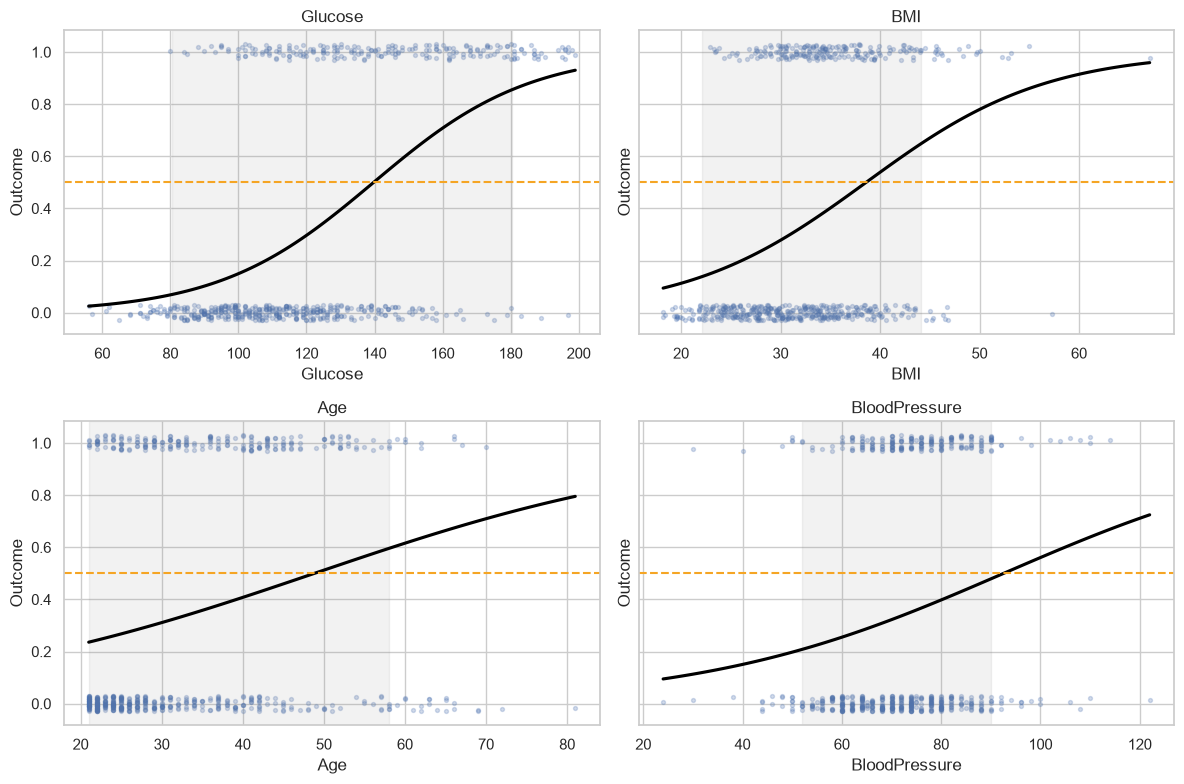

In [17]:
# one logistic regplot per feature
features = ["Glucose", "BMI", "Age", "BloodPressure"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)

for feature, ax in zip(features, axes.ravel()):
    sns.regplot(data=train, x=feature, y="Outcome", y_jitter=0.03, logistic=True, ci=None,
                scatter_kws={"s": 8, "alpha": 0.25}, line_kws={"color": "black"}, ax=ax)
    ax.axhline(0.5, ls="--", color="#F5A524")
    # grey band: where 90 % of the patients are (from the 5th to the 95th percentile)
    ax.axvspan(train[feature].quantile(0.05), train[feature].quantile(0.95), color="grey", alpha=0.1)
    ax.set_title(feature)

plt.tight_layout()
plt.show()

**How to read these four plots**
- **All four curves go up:** higher glucose, BMI, age or blood pressure → higher risk of diabetes.
- **How strong is each feature alone?** Look at how far the curve moves **inside the grey band**:

| feature | P(diabetes) inside the grey band | alone, the feature is… |
|---|---|---|
| Glucose | from 0.07 to 0.86 | **strong**: crosses 0.5 in the middle of the patients |
| BMI | from 0.14 to 0.65 | **medium** |
| Age | from 0.24 to 0.60 | **weaker** |
| BloodPressure | from 0.21 to 0.48 | **weak**: stays below 0.5 for almost everybody |

- ⚠️ The blood-pressure curve crosses 0.5 only at about **93 mm Hg**, where very few patients are. A model with only blood pressure predicts "no diabetes" for **97 %** of the patients: almost the same as the baseline!

> 💡 So a feature can be **informative** (the curve goes up) and still be **too weak alone** to change the decision. In section 5 we combine all features.

### 4.4 The same model with scikit-learn
`regplot` is for **looking**. To **predict** new patients we fit the model with scikit-learn.

Glucose has a few missing values, so we put an **imputer** (fills NaN with the median) in front of the model.

In [18]:
# pipeline: fill missing glucose with the median, then logistic regression
model_glu = make_pipeline(SimpleImputer(strategy="median"), LogisticRegression())
model_glu.fit(X_train[["Glucose"]], y_train)
model_glu.score(X_test[["Glucose"]], y_test)

0.7077922077922078

71 % vs 65 % for the baseline: glucose alone already helps.

The model learned the two numbers of the linear score: $b_0$ (intercept) and $b_1$ (slope).

In [19]:
# b0 and b1 of the linear score z = b0 + b1 * Glucose
b0 = model_glu[-1].intercept_[0]
b1 = model_glu[-1].coef_[0][0]
print(f"b0 = {b0:.2f}   b1 = {b1:.4f}")
print(f"the curve crosses 0.5 where z = 0, so at Glucose = -b0 / b1 = {-b0 / b1:.0f}")

b0 = -6.08   b1 = 0.0436
the curve crosses 0.5 where z = 0, so at Glucose = -b0 / b1 = 140


💡 $p = 0.5$ exactly when $z = 0$, so the border is at glucose $= -b_0 / b_1 \approx 140$: the same crossing point we saw in the regplot.

### 4.5 Probabilities vs classes
- `predict_proba(X)` → **probabilities**: one column per class `[P(0), P(1)]`
- `predict(X)` → the **class**: 1 if P(1) ≥ 0.5, else 0

In [20]:
# the first 5 test patients: glucose, probability of diabetes, predicted class, true class
first5 = X_test[["Glucose"]].head()
pd.DataFrame({
    "Glucose": first5["Glucose"],
    "P(diabetes)": model_glu.predict_proba(first5)[:, 1].round(2),
    "predicted": model_glu.predict(first5),
    "true": y_test.head(),
})

,Glucose,P(diabetes),predicted,true
44,159.0,0.70,1,0
672,68.0,0.04,0,0
700,122.0,0.32,0,0
630,114.0,0.25,0,1
81,74.0,0.05,0,0


🧑‍💻 **Code with me:** what is the probability of diabetes for a patient with glucose **100**? And **150**?

In [21]:
# new patients must have the same column name as in training
new_patients = pd.DataFrame({"Glucose": [100, 150]})
model_glu.predict_proba(new_patients)[:, 1].round(2)

array([0.15, 0.61])

### 4.6 Our scikit-learn S-curve
Let's draw P(diabetes) from **our** model for every glucose value between 40 and 200. It is the same S-curve as in the regplot, now with the decision border marked.

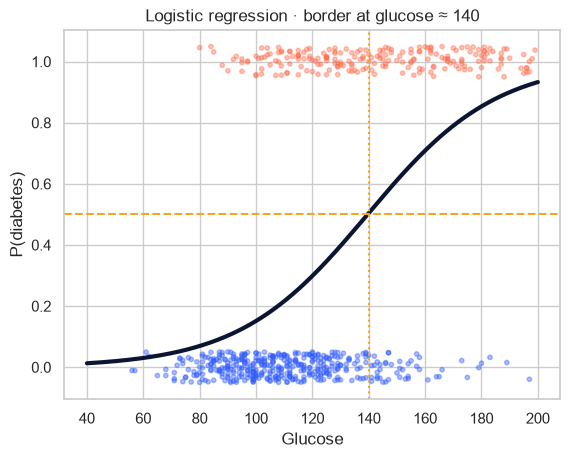

In [22]:
# probability curve over a grid of glucose values
grid = pd.DataFrame({"Glucose": np.linspace(40, 200, 300)})
p_grid = model_glu.predict_proba(grid)[:, 1]

# border: first glucose value where p >= 0.5
border = grid["Glucose"][p_grid >= 0.5].iloc[0]

jitter = np.random.default_rng(0).uniform(-0.05, 0.05, len(y_train))
plt.scatter(X_train["Glucose"], y_train + jitter, c=y_train.map(COLORS), s=10, alpha=0.4)
plt.plot(grid["Glucose"], p_grid, color="#0B1533", lw=3)
plt.axhline(0.5, ls="--", color="#F5A524")
plt.axvline(border, ls=":", color="#F5A524")
plt.xlabel("Glucose"); plt.ylabel("P(diabetes)")
plt.title(f"Logistic regression · border at glucose ≈ {border:.0f}")
plt.show()

💡 Above glucose ≈ 140 the model says "diabetes", below it says "no diabetes". Compare with your guess in section 1!

---
## 5 · Logistic regression with all features
Now all 8 columns. Our pipeline has 3 steps:
1. `SimpleImputer`: fill missing values with the **train** median
2. `StandardScaler`: put every feature on the same scale (mean 0, std 1)
3. `LogisticRegression`: the model

In [23]:
# imputer -> scaler -> logistic regression, on all features
model_lr = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(),
)
model_lr.fit(X_train, y_train)
print("train accuracy:", round(model_lr.score(X_train, y_train), 3))
print("test accuracy: ", round(model_lr.score(X_test, y_test), 3))

train accuracy: 0.796
test accuracy:  0.708


🤔 Surprise: same test accuracy as glucose alone (70.8 %). Does that mean the other features are useless? Keep the question for Thursday: accuracy does not tell us **which** mistakes the model makes.

### 5.1 Reading the coefficients
Because the features are **scaled**, we can compare the coefficients with each other.
- **sign**: `+` raises the probability of diabetes, `−` lowers it
- **size**: bigger = stronger effect

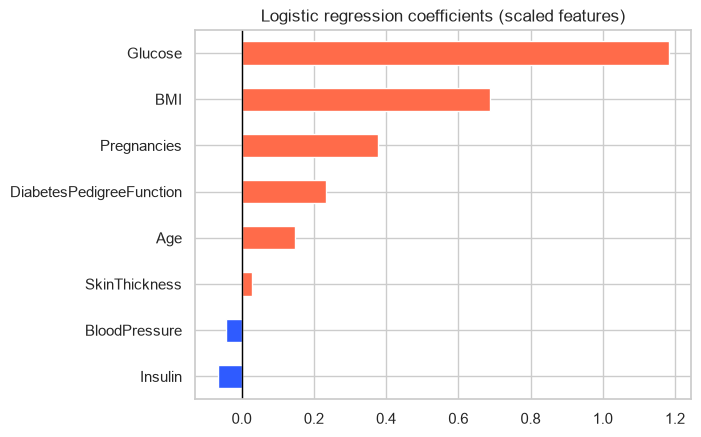

Insulin                    -0.07
BloodPressure              -0.04
SkinThickness               0.03
Age                         0.15
DiabetesPedigreeFunction    0.23
Pregnancies                 0.38
BMI                         0.69
Glucose                     1.18
dtype: float64

In [24]:
# coefficients of the last pipeline step, sorted
coefs = pd.Series(model_lr[-1].coef_[0], index=X.columns).sort_values()
coefs.plot.barh(color=["#FF6B4A" if c > 0 else "#2F5BFF" for c in coefs])
plt.axvline(0, color="black", lw=1)
plt.title("Logistic regression coefficients (scaled features)")
plt.show()
coefs.round(2)

🧑‍💻 **Code with me:** which feature matters most? Which two features barely matter?

> 💡 Glucose dominates, then BMI and pregnancies. Blood pressure and insulin add almost nothing once glucose is known.

---
## 6 · The threshold
`predict()` uses **0.5** by default. But in a screening, missing a sick patient is worse than an extra blood test. We can choose another threshold ourselves.

Two kinds of mistakes:
- **missed case**: the patient has diabetes, the model says 0
- **false alarm**: the patient is healthy, the model says 1

In [25]:
# probabilities of diabetes for the test patients
proba_test = model_lr.predict_proba(X_test)[:, 1]
proba_test[:10].round(2)

array([0.61, 0.12, 0.29, 0.25, 0.03, 0.17, 0.49, 0.92, 0.08, 0.84])

In [26]:
# with a threshold of 0.5 (same as predict)
pred_05 = (proba_test >= 0.5).astype(int)
(pred_05 == model_lr.predict(X_test)).all()

np.True_

🧑‍💻 **Code with me:** for thresholds 0.3, 0.5 and 0.8, count the **caught** diabetes cases, the **missed** cases and the **false alarms**.

In [27]:
# compare three thresholds
n_sick = (y_test == 1).sum()
rows = []
for t in [0.3, 0.5, 0.8]:
    pred = (proba_test >= t).astype(int)
    caught = ((pred == 1) & (y_test == 1)).sum()
    missed = ((pred == 0) & (y_test == 1)).sum()
    false_alarms = ((pred == 1) & (y_test == 0)).sum()
    accuracy = (pred == y_test).mean()
    rows.append([t, caught, missed, false_alarms, round(accuracy, 3)])

pd.DataFrame(rows, columns=["threshold", "caught", "missed", "false alarms", "accuracy"])

,threshold,caught,missed,false alarms,accuracy
0,0.3,43,11,29,0.740
1,0.5,27,27,18,0.708
2,0.8,12,42,6,0.688


💡 Lower threshold → **more cases caught**, but **more false alarms**. Higher threshold → the opposite.
Here 0.3 even gives a slightly higher accuracy, but that is not the point: it catches 43 of 54 diabetes cases instead of 27.
Choosing the threshold is a **clinical or business decision**. On Thursday these counts get a name (the **confusion matrix**) and proper metrics (precision, recall).

---
## 7 · k-Nearest Neighbours (KNN)
To classify a new patient, KNN finds the **k most similar patients** in the training set and takes a **majority vote**.
- `fit()` only **stores** the training data
- "similar" = small **distance** between the feature values

### 7.1 Why scaling matters

In [28]:
# the features live on very different scales
X_train[["Insulin", "DiabetesPedigreeFunction"]].describe().loc[["min", "max"]]

,Insulin,DiabetesPedigreeFunction
min,15.0,0.084
max,744.0,2.329


A difference of 50 in insulin is **huge** in distance; a difference of 0.5 in the family score is tiny. Without scaling, insulin decides everything.

🧑‍💻 **Code with me:** KNN with k = 15, **without** and **with** scaling.

In [29]:
# KNN without scaling
knn_raw = make_pipeline(SimpleImputer(strategy="median"), KNeighborsClassifier(n_neighbors=15))
knn_raw.fit(X_train, y_train)
print("raw features:   ", round(knn_raw.score(X_test, y_test), 3))

# KNN with scaling: only one extra step
knn = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsClassifier(n_neighbors=15))
knn.fit(X_train, y_train)
print("scaled features:", round(knn.score(X_test, y_test), 3))

raw features:    0.656
scaled features: 0.74


💡 66 % → 74 %: same model, same k, only scaling changed. **Distance-based models always need scaled features.**
(Is `StandardScaler` the only option? No: in 7.6 we compare it with `MinMaxScaler`.)

### 7.2 What does k change?
`k` is a **hyperparameter**: **we** choose it, the model does not learn it from the data.

| k | what the model does | risk |
|---|---|---|
| **small** (1, 3) | follows every single neighbour, even the strange ones | **overfitting**: memorises noise |
| **large** (101+) | averages over a huge crowd, the border becomes very smooth | **underfitting**: misses real patterns |
| **in between** | follows the real trend, ignores single outliers | ✅ what we want |

**Two rules of thumb to start**
- Use an **odd k** for two classes: the vote can never be a tie (e.g. 2 vs 2).
- A common first guess is $k \approx \sqrt{n}$, with $n$ = number of training patients.

In [30]:
# rule of thumb: k close to the square root of the number of training patients
n = len(X_train)
print(f"n = {n} training patients -> sqrt(n) = {np.sqrt(n):.1f} -> try k around 25")

n = 614 training patients -> sqrt(n) = 24.8 -> try k around 25


🤔 **Predict:** what is the **training** accuracy of KNN with k = 1?

In [31]:
# k = 1: every training patient is its own nearest neighbour
knn_1 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsClassifier(n_neighbors=1))
knn_1.fit(X_train, y_train)
print("train accuracy, k = 1:", knn_1.score(X_train, y_train))

train accuracy, k = 1: 1.0


> 💡 **100 %**: the model has simply **memorised** the training set. A training score tells us nothing about new patients, so we need **data the model has not seen** to choose k.

> ⚠️ But **not the test set**! The test set is our final exam: if we use it to choose k, it is no longer an honest score. We use the test set **once**, at the very end.

### 7.3 Method 1 · A validation set
We cut the **training set** into two parts again:

| part | patients | used for |
|---|---|---|
| **fit** | 460 | the model learns here |
| **validation** | 154 | we compare the k values here |
| **test** | 154 | 🔒 locked until the end |

🧑‍💻 **Code with me:** split the training set, then try k = 1, 3, 5, …, 99.

In [32]:
# split the TRAINING set: 75 % to fit, 25 % to validate (the test set is not touched)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=42
)
print(len(X_fit), "fit ·", len(X_val), "validation ·", len(X_test), "test (locked)")

460 fit · 154 validation · 154 test (locked)


In [33]:
# for every k: fit on the fit part, score on the fit part and on the validation part
ks = list(range(1, 100, 2))
fit_acc, val_acc = [], []
for k in ks:
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    m.fit(X_fit, y_fit)
    fit_acc.append(m.score(X_fit, y_fit))
    val_acc.append(m.score(X_val, y_val))

best_k_val = ks[np.argmax(val_acc)]
print("best k on the validation set:", best_k_val, "· accuracy:", round(max(val_acc), 3))

best k on the validation set: 31 · accuracy: 0.799


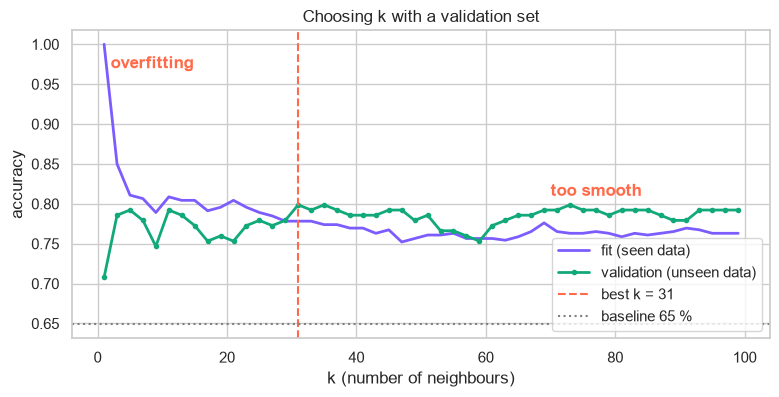

In [34]:
# the validation curve
plt.figure(figsize=(9, 4))
plt.plot(ks, fit_acc, label="fit (seen data)", color="#7C5CFF", lw=2)
plt.plot(ks, val_acc, label="validation (unseen data)", color="#12A97A", lw=2, marker="o", ms=3)
plt.axvline(best_k_val, ls="--", color="#FF6B4A", label=f"best k = {best_k_val}")
plt.axhline(0.649, ls=":", color="grey", label="baseline 65 %")
plt.text(2, 0.97, "overfitting", color="#FF6B4A", fontweight="bold")
plt.text(70, 0.81, "too smooth", color="#FF6B4A", fontweight="bold")
plt.xlabel("k (number of neighbours)"); plt.ylabel("accuracy"); plt.legend(loc="lower right")
plt.title("Choosing k with a validation set")
plt.show()

**How to read this plot**
- **Purple (fit):** 100 % at k = 1 (memorising), then it goes down as k grows.
- **Green (validation):** this is the curve we choose from. It is low at k = 1, rises fast, then stays roughly flat around **75–80 %**.
- The **gap** between purple and green = how much the model overfits. It closes as k grows.
- The green curve **zigzags**: k = 9 gives 75 %, k = 11 gives 79 %. With only 154 validation patients, **one patient more or less right changes the score by 0.65 points**. Part of the "best k" is luck.

🤔 Would we get the **same** best k with a different `random_state` in the split above? Try it!

### 7.4 Method 2 · Cross-validation (preview of Thursday)
To remove the luck, we repeat the validation **5 times**: cut the training set into 5 parts (**folds**), and each part takes a turn as the validation set. Then we **average** the 5 scores.

```
round 1:  [VAL] [fit] [fit] [fit] [fit]
round 2:  [fit] [VAL] [fit] [fit] [fit]
round 3:  [fit] [fit] [VAL] [fit] [fit]
round 4:  [fit] [fit] [fit] [VAL] [fit]
round 5:  [fit] [fit] [fit] [fit] [VAL]
```

`cross_val_score` does the 5 rounds for us. 🧑‍💻 **Code with me:** one k first.

In [35]:
# 5 folds, shuffled once with a fixed seed (more details on Thursday)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

knn_25 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsClassifier(n_neighbors=25))
scores = cross_val_score(knn_25, X_train, y_train, cv=cv)
print("5 validation scores:", scores.round(3))
print(f"mean = {scores.mean():.3f} · std = {scores.std():.3f}")

5 validation scores: [0.789 0.707 0.789 0.772 0.754]
mean = 0.762 · std = 0.030


💡 Same model, same k, five different scores. The **mean** is a more reliable estimate than any single one, and the **std** tells us how much the scores move.

🧑‍💻 **Code with me:** now the mean and std for every k.

In [36]:
# mean and std of the 5 CV scores for every k
cv_mean, cv_std = [], []
for k in ks:
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(m, X_train, y_train, cv=cv)
    cv_mean.append(scores.mean())
    cv_std.append(scores.std())

cv_table = pd.DataFrame({"k": ks, "cv_mean": cv_mean, "cv_std": cv_std})
cv_table.sort_values("cv_mean", ascending=False).head().round(3)

,k,cv_mean,cv_std
6,13,0.775,0.042
7,15,0.769,0.033
11,23,0.769,0.025
8,17,0.767,0.030
33,67,0.766,0.029


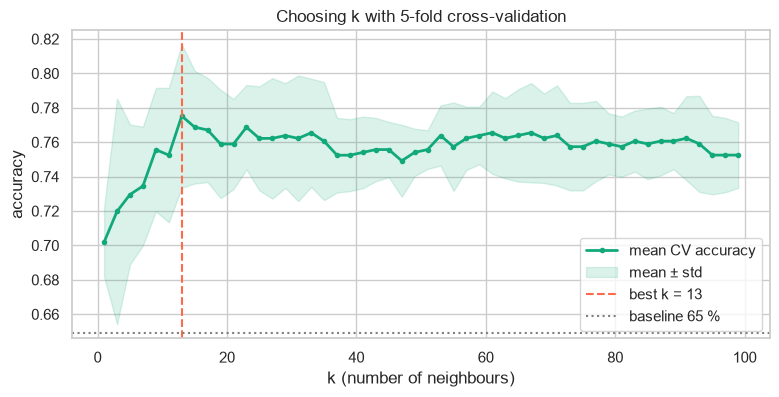

In [37]:
# CV curve: the line is the mean, the band is mean ± std
cv_mean, cv_std = np.array(cv_mean), np.array(cv_std)
best_k = ks[np.argmax(cv_mean)]

plt.figure(figsize=(9, 4))
plt.plot(ks, cv_mean, color="#12A97A", lw=2, marker="o", ms=3, label="mean CV accuracy")
plt.fill_between(ks, cv_mean - cv_std, cv_mean + cv_std, color="#12A97A", alpha=0.15, label="mean ± std")
plt.axvline(best_k, ls="--", color="#FF6B4A", label=f"best k = {best_k}")
plt.axhline(0.649, ls=":", color="grey", label="baseline 65 %")
plt.xlabel("k (number of neighbours)"); plt.ylabel("accuracy"); plt.legend(loc="lower right")
plt.title("Choosing k with 5-fold cross-validation")
plt.show()

**How to read this plot**
- The line is **smoother** than the single validation curve: averaging 5 rounds removes much of the luck.
- Best mean: **k = 13** (77.5 %).
- The **band** (± std, about 4 points) is wider than the differences between most k values from ~11 to ~45: inside this **plateau**, all these k are about **equally good**. Don't over-read a difference of 0.5 points.
- Method 1 picked k = 31, method 2 picks k = 13: **both are on the plateau**. Cross-validation is the more reliable of the two.

**Recipe to choose a hyperparameter**
1. Try several values with **cross-validation on the training set** only.
2. Pick the value with the best **mean** (if several are on the plateau, any of them is fine).
3. **Refit** the model with that value on the **whole training set**.
4. Score it on the **test set once**: that is the honest final score.

### 7.5 The final KNN: refit, then test once

In [38]:
# step 3: refit with the chosen k on the whole training set
final_knn = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
final_knn.fit(X_train, y_train)

# step 4: one honest score on the test set
print(f"k = {best_k} · CV accuracy {cv_mean.max():.3f} · test accuracy {final_knn.score(X_test, y_test):.3f}")

k = 13 · CV accuracy 0.775 · test accuracy 0.714


💡 The test score (71 %) is **lower** than the CV estimate (77.5 %), and even lower than k = 15 in 7.1 (74 %). Should we switch to k = 15 now?

> ❌ **No.** Choosing k **because** of its test score would turn the test set into a validation set, and our "final" score would be too optimistic. The difference between k = 13 and k = 15 is inside the noise band anyway. On Thursday we will see that our test split is a hard one: with 154 patients, one test score moves by several points.

### 7.6 Which scaler? StandardScaler vs MinMaxScaler
Two common ways to put features on the same scale:

| scaler | formula | result |
|---|---|---|
| `StandardScaler` | $\dfrac{x - \text{mean}}{\text{std}}$ | mean 0, std 1 (values can be below −1 or above 3) |
| `MinMaxScaler` | $\dfrac{x - \min}{\max - \min}$ | every value between **0 and 1** |

Both learn their numbers (mean/std or min/max) from the **training set** only, inside the pipeline.

🧑‍💻 **Code with me:** what does each scaler do to `Glucose` and `Insulin`?

In [39]:
from sklearn.preprocessing import MinMaxScaler

# fill the missing values first, then scale with each scaler (training data only)
filled = SimpleImputer(strategy="median").fit_transform(X_train[["Glucose", "Insulin"]])
standard = StandardScaler().fit_transform(filled)
minmax = MinMaxScaler().fit_transform(filled)

pd.DataFrame({
    "Glucose · standard": standard[:, 0], "Insulin · standard": standard[:, 1],
    "Glucose · minmax": minmax[:, 0], "Insulin · minmax": minmax[:, 1],
}).describe().loc[["mean", "std", "min", "25%", "50%", "75%", "max"]].round(2)

,Glucose · standard,Insulin · standard,Glucose · minmax,Insulin · minmax
mean,-0.00,-0.00,0.46,0.17
std,1.00,1.00,0.21,0.11
min,-2.19,-1.56,0.00,0.00
25%,-0.76,-0.22,0.30,0.14
50%,-0.16,-0.16,0.43,0.15
75%,0.61,-0.10,0.59,0.16
max,2.58,7.70,1.00,1.00


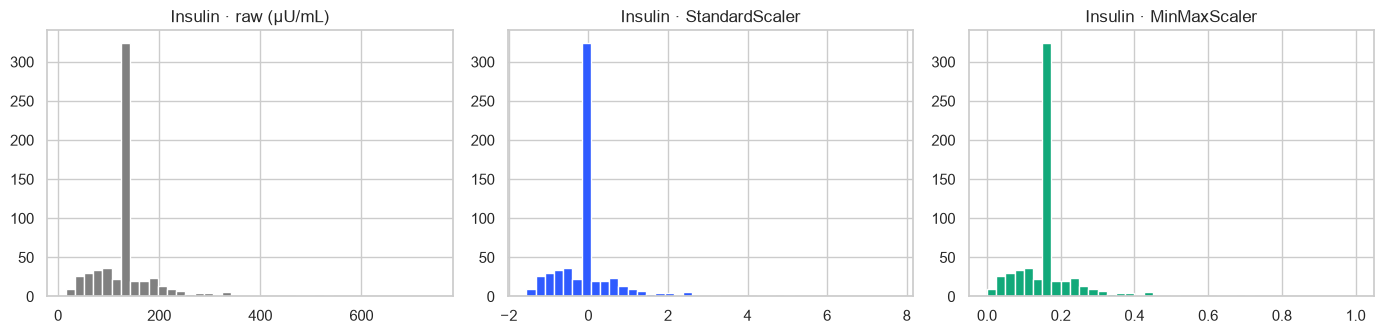

In [40]:
# insulin before and after each scaler: same shape, different numbers on the x-axis
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].hist(filled[:, 1], bins=40, color="grey");      axes[0].set_title("Insulin · raw (µU/mL)")
axes[1].hist(standard[:, 1], bins=40, color="#2F5BFF"); axes[1].set_title("Insulin · StandardScaler")
axes[2].hist(minmax[:, 1], bins=40, color="#12A97A");   axes[2].set_title("Insulin · MinMaxScaler")
plt.tight_layout()
plt.show()

**How to read this**
- A scaler **does not change the shape** of the distribution, only the numbers on the axis.
- The **tall bar** is the same in all three plots: about half of the patients had **no insulin measurement**, and the imputer gave them all the same median value.
- **MinMaxScaler:** the highest insulin value (744, one patient) becomes 1 and the lowest becomes 0. Because of a few extreme values, almost everybody ends up **squeezed between 0 and 0.4**: the extremes decide the scale for everybody.
- **StandardScaler:** centred at 0 with std 1. The bulk of the patients sits between −2 and 2, and the extreme patients just get large values (up to 7.7).

🧑‍💻 **Code with me:** does the choice change the accuracy? We compare no scaling, StandardScaler and MinMaxScaler for **KNN** and for **logistic regression**, with the test score **and** the cross-validation mean.

In [41]:
# helper: imputer -> (optional scaler) -> model
def make_model(scaler, classifier):
    if scaler is None:
        return make_pipeline(SimpleImputer(strategy="median"), classifier)
    return make_pipeline(SimpleImputer(strategy="median"), scaler, classifier)

rows = []
for scaler_name, scaler in [("no scaling", None), ("StandardScaler", StandardScaler()), ("MinMaxScaler", MinMaxScaler())]:
    for model_name, classifier in [("KNN k=15", KNeighborsClassifier(n_neighbors=15)),
                                   ("Logistic regression", LogisticRegression())]:
        model = make_model(scaler, classifier)
        cv_scores = cross_val_score(model, X_train, y_train, cv=cv)
        model.fit(X_train, y_train)
        rows.append({"model": model_name, "scaler": scaler_name,
                     "test accuracy": model.score(X_test, y_test),
                     "CV mean": cv_scores.mean(), "CV std": cv_scores.std()})

scaler_table = pd.DataFrame(rows).sort_values(["model", "CV mean"], ascending=[True, False])
scaler_table.round(3)

/Users/andredeoliveira/ironhack_local/DSML-IH-cohort-october26/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/andredeoliveira/ironhack_local/DSML-IH-cohort-october26/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also wan

,model,scaler,test accuracy,CV mean,CV std
2,KNN k=15,StandardScaler,0.740,0.769,0.033
4,KNN k=15,MinMaxScaler,0.727,0.754,0.027
0,KNN k=15,no scaling,0.656,0.744,0.038
3,Logistic regression,StandardScaler,0.708,0.788,0.019
1,Logistic regression,no scaling,0.734,0.782,0.016
5,Logistic regression,MinMaxScaler,0.708,0.780,0.013


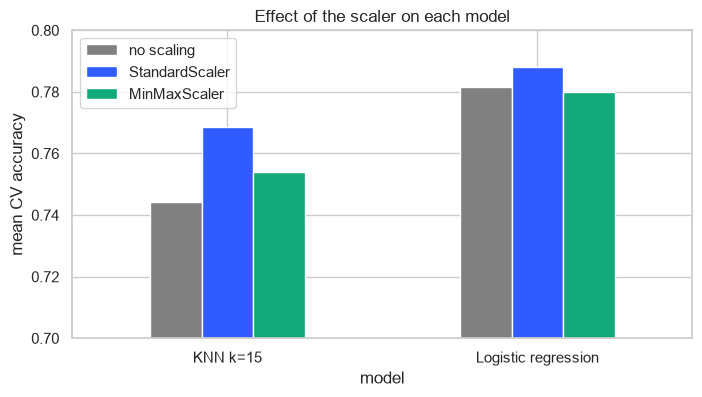

In [42]:
# the same comparison as a bar chart (CV mean)
table = scaler_table.pivot(index="model", columns="scaler", values="CV mean")
table = table[["no scaling", "StandardScaler", "MinMaxScaler"]]     # same order and colours as before
table.plot.bar(rot=0, figsize=(8, 4), color=["grey", "#2F5BFF", "#12A97A"])
plt.ylim(0.70, 0.80); plt.ylabel("mean CV accuracy")
plt.title("Effect of the scaler on each model")
plt.legend(loc="upper left")
plt.show()

**What we learn**
- **KNN:** both scalers clearly beat no scaling (CV 74.4 % → 76.9 % / 75.4 %; test 65.6 % → 74.0 % / 72.7 %). Distances **need** scaling.
- **StandardScaler vs MinMaxScaler for KNN:** Standard is slightly better here (about 1.5 points), probably because the insulin outliers squeeze MinMax. But the difference is **smaller than the CV std (~3 points)**: we cannot call it a real winner.
- **Logistic regression:** the three versions are almost equal in CV (78.0–78.8 %); the test differences (71–73 %) are inside the noise. It does not use distances, so scaling hardly changes its accuracy. We still scale it: did you see the pink **ConvergenceWarning** above? Without scaling, the optimiser that fits the logistic regression struggles to finish. Scaling fixes that and makes the **coefficients comparable** (section 5.1).

**Which scaler should I use?**
- **StandardScaler:** a good default.
- **MinMaxScaler:** when features have natural limits and no big outliers (pixel values 0–255, percentages, ratings 1–5), or when a model needs values between 0 and 1.
- Many outliers? Try `RobustScaler` (uses median and quartiles), same API.
- When in doubt: treat the scaler like k, **compare with cross-validation**, never with the test set.

🧑‍💻 **Code with me:** swapping the model is **one line**. Replace KNN by logistic regression in the pipeline above.

In [43]:
# same pipeline, different last step
swap = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression())
swap.fit(X_train, y_train).score(X_test, y_test)

0.7077922077922078

---
## 8 · Decision boundaries
With **two** features we can draw how each model splits the space. The helper below colours every point of a grid with the predicted class (just run it; no need to understand every line).

In [44]:
def plot_boundary(model, X2, y2, ax, title):
    """Colour the plane by the class predicted by a fitted 2-feature model."""
    gx, gy = np.meshgrid(np.linspace(40, 205, 250), np.linspace(15, 70, 250))
    grid = pd.DataFrame({X2.columns[0]: gx.ravel(), X2.columns[1]: gy.ravel()})
    z = model.predict(grid).reshape(gx.shape)
    ax.contourf(gx, gy, z, levels=[-0.5, 0.5, 1.5], colors=["#C9D6FF", "#FFD3C9"])
    ax.scatter(X2.iloc[:, 0], X2.iloc[:, 1], c=y2.map(COLORS), s=8, alpha=0.6)
    ax.set_xlim(40, 205); ax.set_ylim(15, 70); ax.grid(False)
    ax.set_xlabel(X2.columns[0]); ax.set_ylabel(X2.columns[1]); ax.set_title(title)

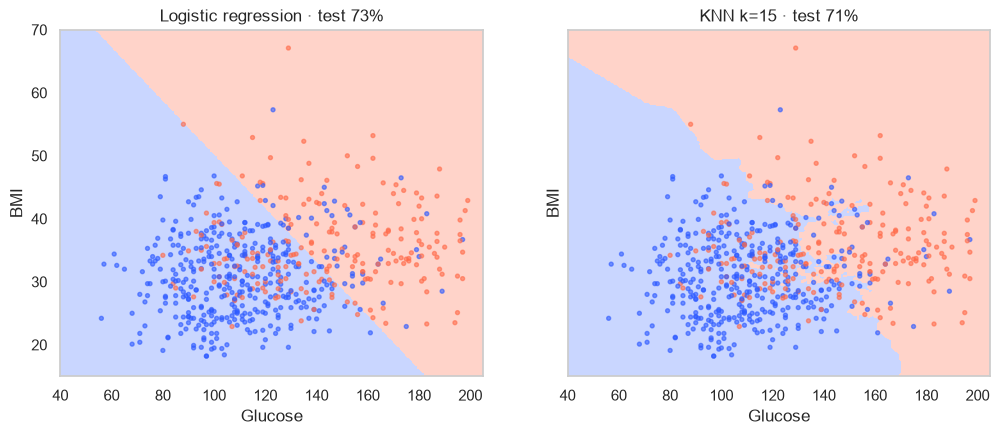

In [45]:
# two features only: Glucose and BMI
two = ["Glucose", "BMI"]
lr2 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression()).fit(X_train[two], y_train)
knn2 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsClassifier(15)).fit(X_train[two], y_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
plot_boundary(lr2, X_train[two], y_train, axes[0], f"Logistic regression · test {lr2.score(X_test[two], y_test):.0%}")
plot_boundary(knn2, X_train[two], y_train, axes[1], f"KNN k=15 · test {knn2.score(X_test[two], y_test):.0%}")
plt.show()

💡 Logistic regression draws **one straight border**. KNN can draw **any shape**: more flexible, it bends to follow the data, and with a small k it also follows the noise. More flexible is not automatically better.

🧑‍💻 Try `KNeighborsClassifier(1)` and `KNeighborsClassifier(151)` in `knn2` and re-run.

---
## 9 · Results table and recap
🧑‍💻 **Code with me:** all our models in one table, sorted by test accuracy.

In [46]:
# one row per model: test accuracy
results = pd.DataFrame({
    "model": ["Baseline (always 0)", "Logistic · glucose only", "Logistic · all features",
              "KNN k=15 · raw", "KNN k=15 · scaled", f"KNN k={best_k} · chosen by CV"],
    "test accuracy": [baseline.score(X_test, y_test),
                      model_glu.score(X_test[["Glucose"]], y_test),
                      model_lr.score(X_test, y_test),
                      knn_raw.score(X_test, y_test),
                      knn.score(X_test, y_test),
                      final_knn.score(X_test, y_test)],
})
results.sort_values("test accuracy", ascending=False).round(3)

,model,test accuracy
4,KNN k=15 · scaled,0.740
5,KNN k=13 · chosen by CV,0.714
1,Logistic · glucose only,0.708
2,Logistic · all features,0.708
3,KNN k=15 · raw,0.656
0,Baseline (always 0),0.649


## 🧭 Recap
| Idea | In code |
|---|---|
| 0 can mean "missing" | `df[cols].replace(0, np.nan)` |
| look at the S-curve first | `sns.regplot(..., logistic=True)` |
| fair split | `train_test_split(..., stratify=y)` |
| always compare to a baseline | `DummyClassifier(strategy="most_frequent")` |
| logistic regression = linear score + sigmoid | `LogisticRegression()` |
| probability vs class | `predict_proba(X)[:, 1]` vs `predict(X)` |
| the threshold is a decision | `(proba >= 0.3).astype(int)` |
| KNN = vote of the k nearest | `KNeighborsClassifier(n_neighbors=15)` |
| distances need scaling | `StandardScaler()` inside the pipeline |
| two scalers, compare with CV | `StandardScaler()` (mean 0, std 1) vs `MinMaxScaler()` (0 to 1) |
| choose k without the test set | validation set or `cross_val_score(model, X_train, y_train, cv=cv)` |
| then refit and test once | `final_knn.fit(X_train, y_train)` → `.score(X_test, y_test)` |
| no leakage | `make_pipeline(imputer, scaler, model)` |

**Thursday:** confusion matrix, precision, recall, F1, ROC-AUC, choosing the threshold, cross-validation in depth.

---
# 📚 Part B · At home
## B1 · Two more classifiers, same API
Every scikit-learn classifier has `.fit()`, `.predict()`, `.predict_proba()`. So trying a new model = changing the last step of the pipeline.
- **SVM** (`SVC`): finds the border with the **widest margin** between the classes
- **Naive Bayes** (`GaussianNB`): computes probabilities with **Bayes' rule**, assuming the features are independent; very fast

In [47]:
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

for name, clf in [("SVM", SVC()), ("Naive Bayes", GaussianNB())]:
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), clf)
    m.fit(X_train, y_train)
    print(f"{name:12} test accuracy: {m.score(X_test, y_test):.3f}")

SVM          test accuracy: 0.740
Naive Bayes  test accuracy: 0.701


## B2 · Exercises (solutions below each one)
**Exercise 1.** Fit KNN with k = 5 and k = 51 (scaled). Print train and test accuracy for both. Which one overfits more?

In [48]:
# Solution 1
for k in [5, 51]:
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsClassifier(k)).fit(X_train, y_train)
    print(f"k={k:2}  train {m.score(X_train, y_train):.3f}  test {m.score(X_test, y_test):.3f}")
# k=5 has the bigger gap between train and test: it overfits more.

k= 5  train 0.829  test 0.753
k=51  train 0.775  test 0.721


**Exercise 2.** Fit a logistic regression with only `Glucose`, `BMI` and `Age`. Is it better or worse than all 8 features? What does that tell you?

In [49]:
# Solution 2
three = ["Glucose", "BMI", "Age"]
m3 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression()).fit(X_train[three], y_train)
print("3 features:", round(m3.score(X_test[three], y_test), 3))
print("8 features:", round(model_lr.score(X_test, y_test), 3))
# A smaller model can be as good: most of the information is in a few features.

3 features: 0.708
8 features: 0.708


**Exercise 3.** A patient has glucose 145, BMI 35 and age 45 (other values unknown). Use `m3` from exercise 2 to give the probability of diabetes and the class with threshold 0.5 and 0.7.

In [50]:
# Solution 3
patient = pd.DataFrame({"Glucose": [145], "BMI": [35], "Age": [45]})
p = m3.predict_proba(patient)[0, 1]
print(f"P(diabetes) = {p:.2f}")
print("threshold 0.5 ->", int(p >= 0.5), "· threshold 0.7 ->", int(p >= 0.7))
# Same patient, different decision: the threshold matters for borderline cases.

P(diabetes) = 0.65
threshold 0.5 -> 1 · threshold 0.7 -> 0


**Exercise 4 (multi-class teaser).** The iris dataset has **3** flower species. Fit a scaled logistic regression and look at `predict_proba` for one flower: how many columns does it have?

In [51]:
# Solution 4
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(iris.data, iris.target, test_size=0.2, stratify=iris.target, random_state=42)
mi = make_pipeline(StandardScaler(), LogisticRegression()).fit(Xi_tr, yi_tr)
print("test accuracy:", round(mi.score(Xi_te, yi_te), 3))
print("probabilities for one flower:", mi.predict_proba(Xi_te.head(1)).round(2))
# 3 columns: one probability per class; they add up to 1. Same code as binary!

test accuracy: 0.933
probabilities for one flower: [[0.98 0.02 0.  ]]
